# Extended Data Fig. 3

Redraws panels a, b, c, e and f of Extended Data Fig. 3 from the figshare source data: worksheets `ED_Fig3a`,
`ED_Fig3b`, `ED_Fig3e` and `ED_Fig3f` of `Wilhelm_SourceData.xlsx`, `Wilhelm_SourceData_ED_Fig3c.parquet` and
`Wilhelm_SourceData_ED_Fig3c_summary.csv`. Panel d is a schematic and has no source data.

Data access: files are downloaded from the figshare article given by `FIGSHARE_ARTICLE_ID` (config cell below or environment variable; set `FIGSHARE_TOKEN` while the article is private) into `./data`, or read from a local copy of the deposit if the environment variable `SOURCE_DATA_DIR` points to it. Panels are saved to `regenerated_panels/ED_Fig3/` (PDF and PNG).

In [1]:
import source_data as sd
from source_data import fetch, readme, table

# figshare article with the source data (https://doi.org/10.6084/m9.figshare.34601982); alternatively set the environment variable
# FIGSHARE_ARTICLE_ID, or SOURCE_DATA_DIR to a local copy of the files. While the article is private, set FIGSHARE_TOKEN.
sd.FIGSHARE_ARTICLE_ID = sd.FIGSHARE_ARTICLE_ID or ""

In [2]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

plt.rcParams['pdf.fonttype'] = 42
DATA = Path('data')
DATA.mkdir(exist_ok=True)
FIG_DIR = Path('regenerated_panels') / 'ED_Fig3'
FIG_DIR.mkdir(parents=True, exist_ok=True)


readme('ED_Fig3')

,Figure,Panel,Worksheet,figshare file(s),Content,Tables in worksheet (top to bottom)
0,Extended Data Fig. 3,a,ED_Fig3a,NaN,95th percentile of the absolute delta iRT per ...,ED_Fig3a
1,Extended Data Fig. 3,b,ED_Fig3b,NaN,Median spectral angle (HCD) per PTM encoding a...,ED_Fig3b
2,Extended Data Fig. 3,c,NaN,Wilhelm_SourceData_ED_Fig3c.parquet; Wilhelm_S...,Spectral angle between a K-trimethylated and a...,NaN
3,Extended Data Fig. 3,e,ED_Fig3e,NaN,One row per amino-acid substitution used for a...,ED_Fig3e
4,Extended Data Fig. 3,f,ED_Fig3f,NaN,Modified residues per peptide spectrum and sin...,ED_Fig3f


## a — iRT prediction error of TMT6-labelled seen PTMs
95th percentile of the absolute delta iRT per PTM encoding and PTM (`abs_dIRT_95pct`). Heatmap with `mako_r` colour map,
logarithmic colour scale from 2 to 40.

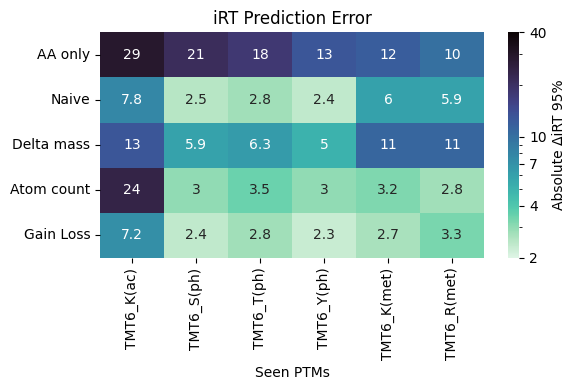

PTM,TMT6_K(ac),TMT6_S(ph),TMT6_T(ph),TMT6_Y(ph),TMT6_K(met),TMT6_R(met)
PTM_encoding,,,,,,
AA only,29.0,21.0,18.0,13.0,12.0,10.0
Naive,7.8,2.5,2.8,2.4,6.0,5.9
Delta mass,13.0,5.9,6.3,5.0,11.0,11.0
Atom count,24.0,3.0,3.5,3.0,3.2,2.8
Gain Loss,7.2,2.4,2.8,2.3,2.7,3.3


In [3]:
from matplotlib.colors import LogNorm
a = table('ED_Fig3a')
rows = ['AA only', 'Naive', 'Delta mass', 'Atom count', 'Gain Loss']
cols = ['TMT6_K(ac)', 'TMT6_S(ph)', 'TMT6_T(ph)', 'TMT6_Y(ph)', 'TMT6_K(met)', 'TMT6_R(met)']
mat = a.pivot(index='PTM_encoding', columns='PTM', values='abs_dIRT_95pct').loc[rows, cols]
fig, ax = plt.subplots(figsize=(6, 4))
sns.heatmap(mat, annot=True, fmt='.2g', cmap='mako_r', norm=LogNorm(vmin=2, vmax=40),
            cbar_kws={'label': 'Absolute ΔiRT 95%', 'ticks': [2, 4, 7, 10, 40], 'format': '%g'}, ax=ax)
ax.set_xlabel('Seen PTMs')
ax.set_ylabel('')
ax.set_title('iRT Prediction Error')
plt.tight_layout()
for ext in ('pdf', 'png'):
    plt.savefig(FIG_DIR / f'ED_Fig3a.{ext}', dpi=300, bbox_inches='tight')
plt.show()
mat

## b — spectral angle of TMT6-labelled seen PTMs per PTM encoding
Median spectral angle of the HCD spectra per PTM encoding and PTM (`median_spectral_angle_HCD`; `n_spectra_HCD` spectra
per cell). Heatmap with `mako` colour map, colour scale from 0.7 to 0.93.

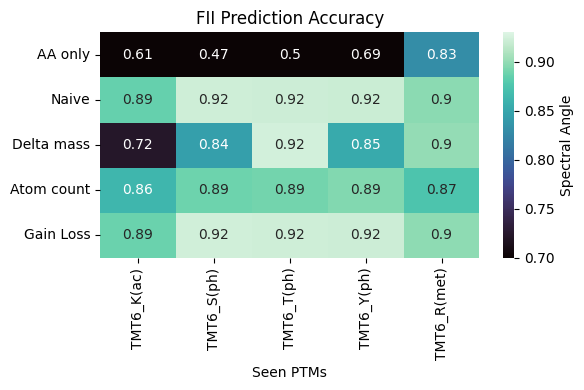

PTM,TMT6_K(ac),TMT6_S(ph),TMT6_T(ph),TMT6_Y(ph),TMT6_R(met)
PTM_encoding,,,,,
AA only,0.61,0.47,0.50,0.69,0.83
Naive,0.89,0.92,0.92,0.92,0.90
Delta mass,0.72,0.84,0.92,0.85,0.90
Atom count,0.86,0.89,0.89,0.89,0.87
Gain Loss,0.89,0.92,0.92,0.92,0.90


In [4]:
b = table('ED_Fig3b')
rows = ['AA only', 'Naive', 'Delta mass', 'Atom count', 'Gain Loss']
cols = ['TMT6_K(ac)', 'TMT6_S(ph)', 'TMT6_T(ph)', 'TMT6_Y(ph)', 'TMT6_R(met)']
mat = b.pivot(index='PTM_encoding', columns='PTM', values='median_spectral_angle_HCD').loc[rows, cols]
fig, ax = plt.subplots(figsize=(6, 4))
sns.heatmap(mat, annot=True, fmt='.2g', cmap='mako', vmin=0.7, vmax=0.93, cbar_kws={'label': 'Spectral Angle'}, ax=ax)
ax.set_xlabel('Seen PTMs')
ax.set_ylabel('')
ax.set_title('FII Prediction Accuracy')
plt.tight_layout()
for ext in ('pdf', 'png'):
    plt.savefig(FIG_DIR / f'ED_Fig3b.{ext}', dpi=300, bbox_inches='tight')
plt.show()
mat.round(2)

## c — spectral angle between K-acetylated and K-trimethylated spectra of the same peptides
Pairs of a K-trimethylated and a K-acetylated spectrum of the same peptide sequence and site (same fragmentation, same
precursor charge, |aligned CE difference| <= 1 NCE). Split violin of `spectral_angle` by `fragmentation`
(`bw_method=0.3`, no inner lines); n pairs per fragmentation from `Wilhelm_SourceData_ED_Fig3c_summary.csv`.

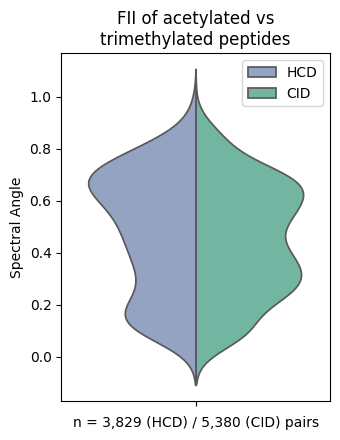

,n_pairs,n_trimethyl_PSMs,n_acetyl_PSMs,n_peptides,median_spectral_angle,Q1_spectral_angle,Q3_spectral_angle
fragmentation,,,,,,,
CID,5380,650,813,102,0.442690,0.278474,0.629752
HCD,3829,755,1013,78,0.515602,0.284709,0.677503


In [5]:
c = pd.read_parquet(fetch('Wilhelm_SourceData_ED_Fig3c.parquet'))
c_sum = table('ED_Fig3c_summary').set_index('fragmentation')
fig, ax = plt.subplots(figsize=(3.5, 4.5))
sns.violinplot(data=c.assign(x=''), x='x', y='spectral_angle', hue='fragmentation', hue_order=['HCD', 'CID'], split=True,
               inner=None, bw_method=0.3, palette={'HCD': '#8da0cb', 'CID': '#66c2a5'}, ax=ax)
n = c_sum['n_pairs']
ax.set_xlabel(f"n = {n['HCD']:,} (HCD) / {n['CID']:,} (CID) pairs")
ax.set_ylabel('Spectral Angle')
ax.set_title('FII of acetylated vs\ntrimethylated peptides')
ax.legend(title='')
plt.tight_layout()
for ext in ('pdf', 'png'):
    plt.savefig(FIG_DIR / f'ED_Fig3c.{ext}', dpi=300, bbox_inches='tight')
plt.show()
c_sum

## e — amino-acid substitutions
One point per amino-acid substitution used for augmentation, coloured by set (train / validation / hold-out);
x = 95th percentile of the absolute delta iRT (`x (absolute delta iRT 95th percentile)`), y = delta mass (Da).

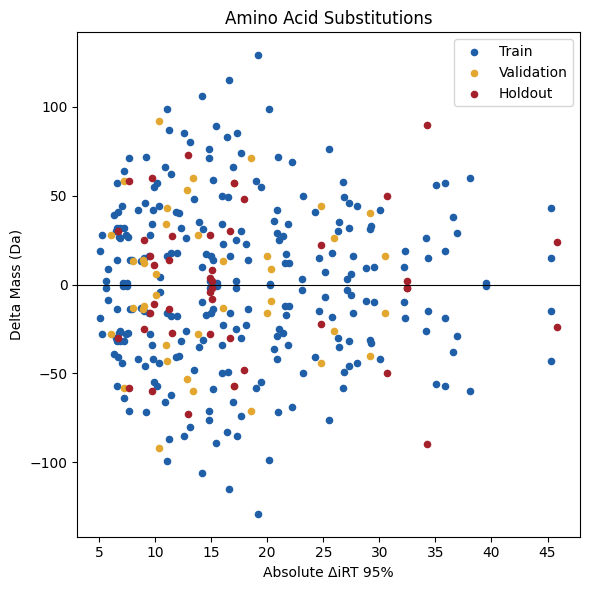

set
Train         258
Holdout        43
Validation     42
Name: count, dtype: int64

In [6]:
e = table('ED_Fig3e')
colors = {'Train': '#1f5fa8', 'Validation': '#e3a72f', 'Holdout': '#a4202a'}
fig, ax = plt.subplots(figsize=(6, 6))
for s, c in colors.items():
    sub = e[e['set'] == s]
    ax.scatter(sub['x (absolute delta iRT 95th percentile)'], sub['delta_mass_Da'], c=c, label=s, s=20)
ax.axhline(0, color='black', linewidth=0.8)
ax.set_xlabel('Absolute ΔiRT 95%')
ax.set_ylabel('Delta Mass (Da)')
ax.set_title('Amino Acid Substitutions')
ax.legend()
plt.tight_layout()
for ext in ('pdf', 'png'):
    plt.savefig(FIG_DIR / f'ED_Fig3e.{ext}', dpi=300, bbox_inches='tight')
plt.show()
e['set'].value_counts()

## f — percentage of modified amino acids and peptides
Percentage of modified residues per amino acid and of singly / doubly modified peptide spectra in the training set with and
without augmentation (oxidation, carbamidomethylation and TMT not counted).

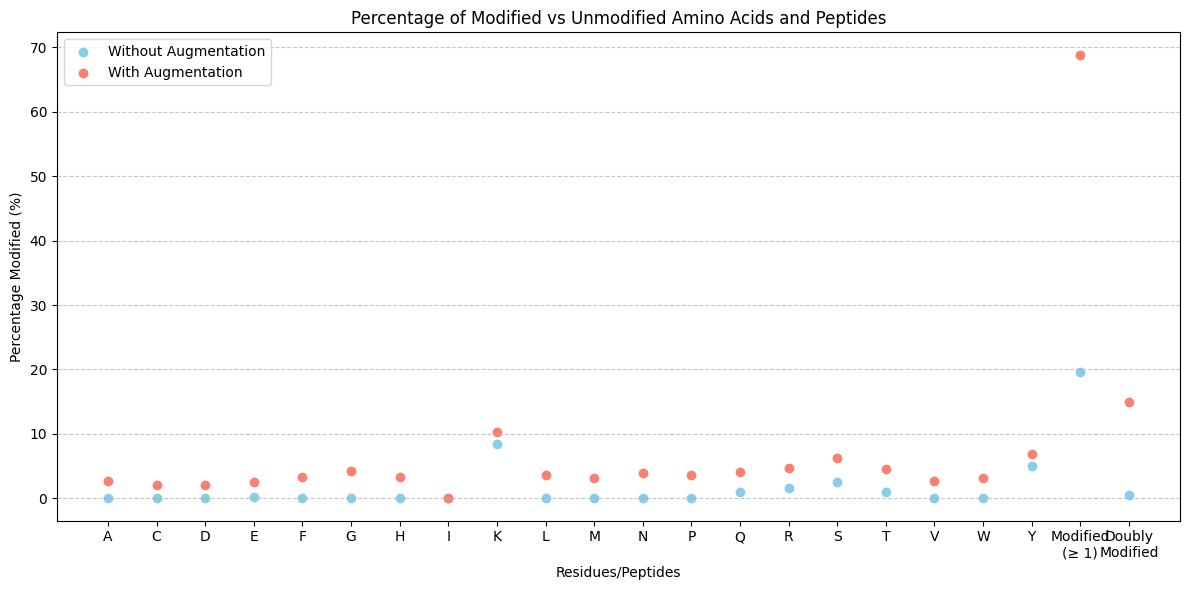

dataset,With Augmentation,Without Augmentation
category,,
A,2.75,0.00
C,2.15,0.00
D,2.01,0.00
E,2.47,0.14
F,3.26,0.00
G,4.19,0.00
H,3.26,0.00
I,0.00,0.00
K,10.36,8.47


In [7]:
f = table('ED_Fig3f')
order = list('ACDEFGHIKLMNPQRSTVWY') + ['Modified (>= 1 modification)', 'Doubly Modified (>= 2 modifications)']
labels = list('ACDEFGHIKLMNPQRSTVWY') + ['Modified\n(≥ 1)', 'Doubly\nModified']
fig, ax = plt.subplots(figsize=(12, 6))
for ds, c in [('Without Augmentation', 'skyblue'), ('With Augmentation', 'salmon')]:
    v = f[f['dataset'] == ds].set_index('category').loc[order, 'percentage_modified_%']
    ax.scatter(range(len(order)), v.values, color=c, label=ds)
ax.set_xticks(range(len(order)), labels)
ax.set_xlabel('Residues/Peptides')
ax.set_ylabel('Percentage Modified (%)')
ax.set_title('Percentage of Modified vs Unmodified Amino Acids and Peptides')
ax.grid(axis='y', linestyle='--', alpha=0.7)
ax.legend()
plt.tight_layout()
for ext in ('pdf', 'png'):
    plt.savefig(FIG_DIR / f'ED_Fig3f.{ext}', dpi=300, bbox_inches='tight')
plt.show()
f.pivot(index='category', columns='dataset', values='percentage_modified_%').loc[order].round(2)